# Práctica 2. Procesamiento de datos.

### Lucy Torres Durante

### dataset de https://the-eye.eu/redarcs/

Obtuve el dataset de https://the-eye.eu/redarcs/ en 2025 para una practica de mineria de datos en licenciatura, hoy en dia el servidor sufrio una falla de hardware y aun no se puede ver. Pero se pueden sacar los mismos datos de https://arctic-shift.photon-reddit.com

In [1]:
import os
import zstandard as zstd

INPUT_DIR = "zsts"
OUTPUT_DIR = "output"

os.makedirs(OUTPUT_DIR, exist_ok=True)

dctx = zstd.ZstdDecompressor()

for filename in os.listdir(INPUT_DIR):
    if not filename.endswith(".zst"):
        continue

    input_path = os.path.join(INPUT_DIR, filename)
    # Strip the .zst extension and add .jsonl
    output_name = os.path.splitext(filename)[0] + ".jsonl"
    output_path = os.path.join(OUTPUT_DIR, output_name)

    with open(input_path, "rb") as fh_in:
        with dctx.stream_reader(fh_in) as reader:
            with open(output_path, "wb") as fh_out:
                # Stream in chunks to handle large files
                while chunk := reader.read(1 << 20):  # 1 MB chunks
                    fh_out.write(chunk)

    print(f"Decompressed {input_path} -> {output_path}")

Decompressed zsts/MtF_comments.zst -> output/MtF_comments.jsonl
Decompressed zsts/traaaaaaannnnnnnnnns_comments.zst -> output/traaaaaaannnnnnnnnns_comments.jsonl
Decompressed zsts/traaaaaaannnnnnnnnns_submissions.zst -> output/traaaaaaannnnnnnnnns_submissions.jsonl
Decompressed zsts/egg_irl_comments.zst -> output/egg_irl_comments.jsonl
Decompressed zsts/MtF_submissions.zst -> output/MtF_submissions.jsonl
Decompressed zsts/asktransgender_submissions.zst -> output/asktransgender_submissions.jsonl
Decompressed zsts/asktransgender_comments.zst -> output/asktransgender_comments.jsonl
Decompressed zsts/egg_irl_submissions.zst -> output/egg_irl_submissions.jsonl


In [ ]:
Los archivos comprimidos vienen en formato jsonl. por lo que podemos usar pandas para leerlo.

In [6]:
import pandas as pd

print(f"File size: {os.path.getsize("output/MtF_submissions.jsonl") / 1024**2:.2f} MB")
df = pd.read_json("output/MtF_submissions.jsonl", lines=True)
print(df.columns.tolist())
print(df.head())

File size: 615.04 MB
['downs', 'link_flair_text', 'distinguished', 'media', 'url', 'link_flair_css_class', 'id', 'edited', 'num_reports', 'created_utc', 'banned_by', 'name', 'subreddit', 'title', 'author_flair_text', 'is_self', 'author', 'media_embed', 'permalink', 'author_flair_css_class', 'selftext', 'domain', 'num_comments', 'likes', 'clicked', 'thumbnail', 'saved', 'subreddit_id', 'ups', 'approved_by', 'score', 'selftext_html', 'created', 'hidden', 'over_18', 'secure_media_embed', 'gilded', 'mod_reports', 'report_reasons', 'stickied', 'user_reports', 'retrieved_on', 'secure_media', 'hide_score', 'quarantine', 'from_id', 'from_kind', 'from', 'archived', 'post_hint', 'preview', 'locked', 'contest_mode', 'spoiler', 'suggested_sort', 'brand_safe', 'author_cakeday', 'view_count', 'thumbnail_height', 'can_gild', 'thumbnail_width', 'is_video', 'approved_at_utc', 'banned_at_utc', 'can_mod_post', 'is_crosspostable', 'num_crossposts', 'parent_whitelist_status', 'whitelist_status', 'is_reddit

Descargue posts de reddit de 4 subreddits:
1. r/egg_irl
2. r/MtF
3. r/ask_transgender
4. r/traaaaaaannnnnnnnnns

Los cuales me permitiran tener un analisis sobre la comunidad trans anglosajona. Espero poder ver tendencias en el sentimiento a lo largo del tiempo.

Viendo todas las columnas que hay, vemos que hay muchas que no nos interesan, en el siguiente script se hace filtrado y extraccion de caracteristicas.

In [1]:
import os
import re
import json
import csv
import string
import hashlib
from glob import glob
from datetime import datetime, timezone

import emoji
from textblob import TextBlob
from tqdm import tqdm

# ============================================================
# Config
# ============================================================
INPUT_DIR  = "output"
OUTPUT_DIR = "output"
OUT_FILE   = os.path.join(OUTPUT_DIR, "all_data.csv")

COMPUTE_SENTIMENT = True   # set False for ~10x speedup on the first pass

# ============================================================
# Helpers
# ============================================================
def file_type(path):
    name = os.path.basename(path).lower()
    if "submission" in name: return "submission"
    #if "comment"    in name: return "comment"
    return None

def anon(user):
    """Stable, anonymous 12-char hash of a username. None if missing/deleted."""
    if user in (None, "", "[deleted]"): return None
    return hashlib.sha256(user.encode("utf-8")).hexdigest()[:12]

def is_deleted(user):
    """1 if the raw author field is the literal '[deleted]' marker."""
    return 1 if user == "[deleted]" else 0

def ts_to_year(ts):
    if ts is None: return None
    try:
        return datetime.fromtimestamp(int(ts), tz=timezone.utc).year
    except (ValueError, TypeError, OSError):
        return None

# ============================================================
# Static image URLs (jpg / jpeg / png only — no gifs, no videos)
# ============================================================
STATIC_EXTS = r'(?:jpg|jpeg|png)'
STATIC_IMAGE_RE = re.compile(
    r'https?://'
    r'(?:i\.redd\.it/|preview\.redd\.it/|external-preview\.redd\.it/|i\.imgur\.com/)'
    r'[^\s\)\]\}"\']+\.' + STATIC_EXTS,
    re.I,
)
IMGUR_BARE_RE  = re.compile(r'https?://(?:i\.)?imgur\.com/([A-Za-z0-9]+)(?![./\w-])', re.I)
IMGUR_ALBUM_RE = re.compile(r'https?://imgur\.com/(?:a|gallery)/', re.I)
GIF_HOST_RE    = re.compile(r'(giphy\.com|tenor\.com|gfycat\.com)', re.I)

def extract_static_image_urls(item):
    """Return a list of direct static-image URLs found in a submission or comment."""
    urls = []

    is_submission = "title" in item and ("selftext" in item or "url" in item)
    if is_submission:
        if item.get("is_video") or item.get("is_gallery"):
            return []
        if item.get("post_hint") in ("rich:video", "hosted:video"):
            return []
        url = item.get("url") or ""
        if url and not GIF_HOST_RE.search(url) and STATIC_IMAGE_RE.match(url):
            urls.append(url.rstrip('.,;:!?'))

    text = item.get("body") or item.get("selftext") or ""
    if isinstance(text, str) and text:
        for m in STATIC_IMAGE_RE.finditer(text):
            urls.append(m.group(0).rstrip('.,;:!?'))
        for m in IMGUR_BARE_RE.finditer(text):
            if IMGUR_ALBUM_RE.match(m.group(0)):
                continue
            urls.append(f"https://i.imgur.com/{m.group(1)}.jpg")

    seen, out = set(), []
    for u in urls:
        if u not in seen:
            seen.add(u)
            out.append(u)
    return out

# ============================================================
# Text features
# ============================================================
def extract_text_features(text):
    if text is None:
        return {
            'text_length': 0, 'word_count': 0,
            'question_mark_count': 0, 'exclamation_mark_count': 0,
            'sentiment_score': None, 'sentiment_subjectivity': None,
            'avg_word_length': 0, 'unique_word_ratio': 0,
            'uppercase_ratio': 0, 'punctuation_count': 0,
            'has_url': 0, 'has_mention': 0, 'has_emoji': 0,
            'caps_words_count': 0, 'has_suggested_subreddit': 0,
            'suggested_subreddit': [],
        }

    text = str(text)
    has_emoji_val = 1 if emoji.emoji_list(text) else 0
    text = emoji.demojize(text)

    text_length          = len(text)
    words                = text.split()
    word_count           = len(words)
    question_mark_count  = text.count('?')
    exclamation_mark_count = text.count('!')
    punctuation_count    = sum(1 for c in text if c in string.punctuation)

    if COMPUTE_SENTIMENT:
        try:
            blob = TextBlob(text)
            sentiment_score, sentiment_subjectivity = blob.sentiment
        except Exception:
            sentiment_score, sentiment_subjectivity = None, None
    else:
        sentiment_score, sentiment_subjectivity = None, None

    avg_word_length   = sum(len(w) for w in words) / word_count if word_count else 0
    unique_words      = len(set(w.lower() for w in words))
    unique_word_ratio = unique_words / word_count if word_count else 0
    uppercase_chars   = sum(1 for c in text if c.isupper())
    uppercase_ratio   = uppercase_chars / len(text) if text else 0
    caps_words        = sum(1 for w in words if w.isupper() and len(w) > 1)

    has_url       = 1 if re.search(r'http[s]?://|www\.', text) else 0
    has_mention   = 1 if re.search(r'/u/|u/|@', text) else 0
    suggested_sub = re.findall(r'\br/([a-zA-Z0-9_]+)', text, re.IGNORECASE)

    return {
        'text_length': text_length,
        'word_count': word_count,
        'question_mark_count': question_mark_count,
        'exclamation_mark_count': exclamation_mark_count,
        'sentiment_score': sentiment_score,
        'sentiment_subjectivity': sentiment_subjectivity,
        'avg_word_length': avg_word_length,
        'unique_word_ratio': unique_word_ratio,
        'uppercase_ratio': uppercase_ratio,
        'punctuation_count': punctuation_count,
        'has_url': has_url,
        'has_mention': has_mention,
        'has_emoji': has_emoji_val,
        'caps_words_count': caps_words,
        'has_suggested_subreddit': 1 if suggested_sub else 0,
        'suggested_subreddit': suggested_sub,
    }

# ============================================================
# Canonical column order
# ============================================================
COLUMNS = [
    # identity / routing
    "type", "id", "author_id", "author_deleted", "author",
    # time
    "created_utc", "created_year",
    "author_created_utc",
    # location
    "subreddit",
    # content
    "title", "text", "is_self",
    # thread structure
    "link_id", "parent_id", "is_submitter",
    # engagement
    "score", "upvote_ratio", "num_comments",
    "gilded", "total_awards_received",
    "controversiality",
    # flair
    "author_flair_text", "link_flair_text",
    # media
    "image_count", "image_urls",
    # text features
    "text_length", "word_count",
    "question_mark_count", "exclamation_mark_count",
    "sentiment_score", "sentiment_subjectivity",
    "avg_word_length", "unique_word_ratio", "uppercase_ratio",
    "punctuation_count", "has_url", "has_mention", "has_emoji",
    "caps_words_count", "has_suggested_subreddit", "suggested_subreddit",
]

# ============================================================
# Row builders
# ============================================================
def submission_row(post):
    text   = post.get("selftext")
    feats  = extract_text_features(text)
    imgs   = extract_static_image_urls(post)
    author = post.get("author")

    return {
        "type": "submission",
        "id": post.get("id"),
        "author_id": anon(author),
        "author_deleted": is_deleted(author),
        "author": author,

        "created_utc": post.get("created_utc"),
        "created_year": ts_to_year(post.get("created_utc")),
        "author_created_utc": post.get("author_created_utc"),

        "subreddit": post.get("subreddit"),

        "title":   post.get("title"),
        "text":    text,
        "is_self": post.get("is_self"),

        "link_id":      None,
        "parent_id":    None,
        "is_submitter": None,

        "score":         post.get("score"),
        "upvote_ratio":  post.get("upvote_ratio"),
        "num_comments":  post.get("num_comments"),
        "gilded":        post.get("gilded"),
        "total_awards_received": post.get("total_awards_received"),
        "controversiality": None,

        "author_flair_text":     post.get("author_flair_text"),
        "link_flair_text":       post.get("link_flair_text"),

        "image_count": len(imgs),
        "image_urls":  imgs,

        **feats,
    }


def comment_row(c):
    text   = c.get("body")
    feats  = extract_text_features(text)
    imgs   = extract_static_image_urls(c)
    author = c.get("author")

    return {
        "type": "comment",
        "id": c.get("id"),
        "author_id": anon(author),
        "author_deleted": is_deleted(author),
        "author": author,

        "created_utc": c.get("created_utc"),
        "created_year": ts_to_year(c.get("created_utc")),
        "author_created_utc": c.get("author_created_utc"),

        "subreddit": c.get("subreddit"),

        "title":   None,
        "text":    text,
        "is_self": None,

        "link_id":      c.get("link_id"),
        "parent_id":    c.get("parent_id"),
        "is_submitter": c.get("is_submitter"),

        "score":         c.get("score"),
        "upvote_ratio":  None,
        "num_comments":  None,
        "gilded":        c.get("gilded"),
        "total_awards_received": c.get("total_awards_received"),
        "controversiality": c.get("controversiality"),

        "author_flair_text":     c.get("author_flair_text"),
        "link_flair_text":       None,

        "image_count": len(imgs),
        "image_urls":  imgs,

        **feats,
    }

# ============================================================
# Stream everything into ONE CSV
# ============================================================
LIST_FIELDS = ("suggested_subreddit", "image_urls")

paths = sorted(glob(os.path.join(INPUT_DIR, "*.jsonl")))
paths = [p for p in paths if file_type(p) is not None]

print(f"Found {len(paths)} jsonl files. Writing -> {OUT_FILE}\n")

with open(OUT_FILE, "w", encoding="utf-8", newline="") as fout:
    writer = csv.DictWriter(fout, fieldnames=COLUMNS, extrasaction="ignore")
    writer.writeheader()

    for path in paths:
        kind = file_type(path)
        build_row = submission_row if kind == "submission" else comment_row
        stem = os.path.basename(path)

        with open(path, "r", encoding="utf-8", errors="replace") as fin:
            for line in tqdm(fin, desc=stem, unit="rows"):
                try:
                    obj = json.loads(line)
                except json.JSONDecodeError:
                    continue

                row = build_row(obj)
                for k in LIST_FIELDS:
                    v = row.get(k)
                    if isinstance(v, (list, dict)):
                        row[k] = json.dumps(v, ensure_ascii=False)

                writer.writerow(row)

print(f"\nDone. Wrote {OUT_FILE}  ({os.path.getsize(OUT_FILE)/1e9:.2f} GB)")

Found 4 jsonl files. Writing -> output/all_data.csv



MtF_submissions.jsonl: 241223rows [03:40, 1094.39rows/s]
asktransgender_submissions.jsonl: 394184rows [07:20, 895.60rows/s] 
egg_irl_submissions.jsonl: 152651rows [00:15, 9828.74rows/s]
traaaaaaannnnnnnnnns_submissions.jsonl: 401414rows [00:42, 9530.51rows/s] 


Done. Wrote output/all_data.csv  (0.71 GB)


Al final decidi trabajar unicamente con los posts por que los comentarios pueden agregar mas ruido del esperado. entre los comentarios de bots y las personas, no se sabe si tendran un valor. Agregue las columnas:

text length, word count, question mark count, exclamation mark count, sentiment score, sentiment subjectivity, avg word length, unique word ratio, uppercase ratio, punctuation count, has url, has mention, has emoji, caps words count, has suggested subreddit, suggested subreddit

Para ver si hacer podemos extraer informacion importante de ella. La mas importante a mi parecer son sentiment score y sentiment subjectivity de textblob, las cuales hacen un analisis de sentimientos basandose en un lexicon pre definido donde cada palabra tiene un cierto score, luego se aplican ciertas reglas de gramatica donde si viene una negacion, flipea el valor de la palabra, y al final da un promedio y lo entrega en un valor entre 0 y 1. Es muy similar a bag of words o VADER, en el sentido que usa lexicones, por lo que problemas como el sarcasmo, la ironia, contexto y ambiguedad, slang y otras cosas son problemas grandes con el.

In [28]:
import pandas as pd
df = pd.read_csv("output/all_data.csv", low_memory=False)
print(df["type"].value_counts())
print("unique ids:", df["id"].nunique())
print("total rows:", len(df))

type
submission    1189472
Name: count, dtype: int64
unique ids: 1189472
total rows: 1189472


In [29]:
print(df.shape)      # (rows, columns)
print(df.head())     # first 5 rows
print(df.dtypes)     # column types
print(df.columns.tolist())  # column names

(1189472, 41)
         type      id     author_id  author_deleted          author  \
0  submission   v5lqc           NaN               1       [deleted]   
1  submission  1amexp           NaN               1       [deleted]   
2  submission  1alhmi           NaN               1       [deleted]   
3  submission  1msi6c  148f8bb01013               0      Audrey1989   
4  submission  1mtizy  2aa23f259a61               0  AccountHaver25   

   created_utc  created_year  author_created_utc subreddit  \
0   1339885883          2012                 NaN       MtF   
1   1363731310          2013                 NaN       MtF   
2   1363706780          2013                 NaN       MtF   
3   1379700913          2013                 NaN       MtF   
4   1379734671          2013                 NaN       MtF   

                                               title  ... avg_word_length  \
0  I know I shouldn't post because the mods haven...  ...        4.076923   
1                               

In [55]:
pattern = r'^\s*\[\s*(?:deleted|removed)|removed by reddit'

bad = df['text'].str.contains(pattern, case=False, na=False, regex=True)

filtered_df = df[
    (df['num_comments'] > 1) &
    (df['score'] > 5) &
    (df['image_count'] == 0) &
    (df['text'].notna()) &
    (~bad)
].copy()

print(filtered_df.shape)      # (rows, columns)
print(filtered_df.head())     # first 5 rows
print(filtered_df.dtypes)     # column types
print(filtered_df.columns.tolist())  # column names
print(f"Original rows: {len(df):,}")
print(f"Filtered rows: {len(filtered_df):,}")
print(f"Percentage kept: {len(filtered_df)/len(df)*100:.2f}%")

(210430, 41)
          type      id     author_id  author_deleted          author  created_utc  created_year  author_created_utc subreddit  \
7   submission  1oqucu  61f06863177f               0  sky_falls_down   1382136827          2013                 NaN       MtF   
8   submission  1oqad8  cc0d8c6f08f1               0  FinlyErkenwald   1382120738          2013                 NaN       MtF   
9   submission  1oq4mw  957e08420b0d               0       AngElSkyy   1382116287          2013                 NaN       MtF   
10  submission  1opy76  928ef78f469a               0     lovepink108   1382111298          2013                 NaN       MtF   
15  submission  1op3rd           NaN               1       [deleted]   1382071957          2013                 NaN       MtF   

                                                                                                        title  ... avg_word_length  unique_word_ratio  uppercase_ratio  punctuation_count  has_url  \
7             

Filtramos por posts que tengan al menos 1 comentario, 5 de score y 0 imagenes y que el cuerpo del post no este borrado, para trabajar unicamente con texto. Y perdimos un 82.31% de los datos, con un total sobrante de 210.445 posts.

ademas, vamos a droppear columnas que no nos sirven para los post, y para mantener el anonimato de las personas de reddit.

In [56]:
filtered_df = filtered_df.drop(columns=['type', 'author_id', 'author_deleted', 'author', 'created_year', 'is_self', 'link_id', 'parent_id', 'is_submitter', 'controversiality', 'image_urls', 'has_mention', 'has_url', 'has_suggested_subreddit', 'suggested_subreddit', 'image_count'])

print(filtered_df.shape)      # (rows, columns)
print(filtered_df.head())     # first 5 rows
print(filtered_df.dtypes)     # column types
print(filtered_df.columns.tolist())  # column names

print(f"Filtered rows: {len(filtered_df):,}")



(210430, 25)
        id  created_utc  author_created_utc subreddit                                                                                                      title  \
7   1oqucu   1382136827                 NaN       MtF                                                                                      eating with long hair   
8   1oqad8   1382120738                 NaN       MtF  "Crap, that's triggering too" &gt;_&lt; (trigger warning, but also meant to be a place to laugh about it)   
9   1oq4mw   1382116287                 NaN       MtF                                                                                        Rant/Im in a pickle   
10  1opy76   1382111298                 NaN       MtF                                                                      So, we should hang out here and stuff   
15  1op3rd   1382071957                 NaN       MtF                                                                   Getting hormones is far too difficult...   

  

In [57]:
# Count NaNs per column
print(filtered_df[['sentiment_score', 'sentiment_subjectivity']].isna().sum())

# Total invalid rows (NaN in either column)
print(filtered_df[['sentiment_score', 'sentiment_subjectivity']].isna().any(axis=1).sum())

sentiment_score           0
sentiment_subjectivity    0
dtype: int64
0


### vamos a imprimir un top 5 mejores y peores post por subreddit.

In [58]:
from IPython.display import display, HTML
import html
from datetime import datetime, timezone

def render_post(row, rank):
    """Render a single post as Reddit-style HTML with expandable text."""
    title = html.escape(str(row['title']) if pd.notna(row['title']) else '[no title]')
    text = str(row['text']) if pd.notna(row['text']) else ''
    text = html.escape(text)
    author_flair = row.get('author_flair_text')
    link_flair = row.get('link_flair_text')

    # --- Created date (shown as-is) ---
    created_utc = row.get('created_utc')
    if pd.notna(created_utc):
        dt = datetime.fromtimestamp(float(created_utc), tz=timezone.utc)
        created_str = dt.strftime('%b %d, %Y · %H:%M UTC')
        created_html = f'<span>🕒 {created_str}</span>'
    else:
        created_html = '<span>🕒 unknown</span>'

    # --- Sentiment values (plain text) ---
    sent_score = row.get('sentiment_score')
    sent_subj = row.get('sentiment_subjectivity')

    sent_html = f'<span>sentiment: {sent_score:.2f}</span>'
    subj_html = f'<span>subjectivity: {sent_subj:.2f}</span>'

    preview = text[:300] + ('…' if len(text) > 300 else '')

    if len(text) <= 300:
        text_html = f'<div style="color:#1a1a1b;font-size:13px;line-height:1.5;margin-bottom:10px;">{text}</div>'
    else:
        text_html = f"""
        <details style="margin-bottom:10px;">
            <summary style="cursor:pointer;color:#0079d3;font-size:12px;
                            user-select:none;outline:none;margin-bottom:6px;">
                ▶ Show full text ({len(text):,} chars)
            </summary>
            <div style="color:#1a1a1b;font-size:13px;line-height:1.5;
                        margin-top:6px;white-space:pre-wrap;">
                {text}
            </div>
        </details>
        <div style="color:#787c7e;font-size:13px;line-height:1.5;
                    margin-bottom:10px;font-style:italic;">
            {preview}
        </div>
        """

    author_flair_html = (
        f'<span style="background:#edeff1;color:#1c1c1c;padding:1px 6px;'
        f'border-radius:10px;font-size:11px;margin-left:6px;">'
        f'{html.escape(str(author_flair))}</span>'
    ) if pd.notna(author_flair) and author_flair else ''

    link_flair_html = (
        f'<span style="background:#0079d3;color:white;padding:2px 8px;'
        f'border-radius:12px;font-size:11px;font-weight:600;'
        f'margin-right:8px;">{html.escape(str(link_flair))}</span>'
    ) if pd.notna(link_flair) and link_flair else ''

    score = int(row['score']) if pd.notna(row['score']) else 0
    gilded = int(row['gilded']) if pd.notna(row['gilded']) else 0
    awards = int(row['total_awards_received']) if pd.notna(row['total_awards_received']) else 0
    comments = int(row['num_comments']) if pd.notna(row['num_comments']) else 0

    arrow_color = '#ff4500' if score >= 0 else '#7193ff'

    return f"""
    <div style="border:1px solid #ccc;border-radius:8px;padding:12px;
                margin-bottom:10px;background:#fff;font-family:'IBM Plex Sans',Arial,sans-serif;">
        <div style="color:#787c7e;font-size:12px;margin-bottom:6px;">
            #{rank}
        </div>
        <div style="margin-bottom:6px;">
            {link_flair_html}
            <span style="font-size:17px;font-weight:600;color:#1a1a1b;">{title}</span>
            {author_flair_html}
        </div>
        {text_html}
        <div style="color:#787c7e;font-size:12px;display:flex;gap:16px;flex-wrap:wrap;align-items:center;">
            <span style="color:{arrow_color};font-weight:700;">
                ▲ {score:,}
            </span>
            <span>💬 {comments:,} comments</span>
            <span>🏅 {gilded} gilded</span>
            <span>🎖️ {awards} awards</span>
            {sent_html}
            {subj_html}
            {created_html}
        </div>
    </div>
    """


def render_section(df, heading):
    parts = [
        f'<h3 style="color:#1a1a1b;font-family:Arial,sans-serif;'
        f'border-bottom:2px solid #ff4500;padding-bottom:4px;">{heading}</h3>'
    ]
    for i, (_, row) in enumerate(df.iterrows(), start=1):
        parts.append(render_post(row, i))
    return ''.join(parts)


# Make sure created_utc is included
display_cols = [
    'title', 'text', 'score', 'gilded', 'num_comments',
    'total_awards_received', 'author_flair_text', 'link_flair_text',
    'created_utc', 'sentiment_score','sentiment_subjectivity'
]

for subreddit, group in filtered_df.groupby('subreddit'):
    header = f"""
    <div style="background:#0079d3;color:white;padding:14px 18px;
                border-radius:8px;margin-top:24px;font-family:Arial,sans-serif;">
        <span style="font-size:14px;opacity:0.85;">r/</span>
        <span style="font-size:22px;font-weight:700;">{html.escape(str(subreddit))}</span>
        <span style="font-size:13px;opacity:0.85;margin-left:12px;">
            {len(group):,} posts
        </span>
    </div>
    """

    top5 = group.nlargest(5, 'score')[display_cols]
    bottom5 = group.nsmallest(5, 'score')[display_cols]

    best_html = render_section(top5, "🔥 Top 5 Best (highest score)")
    worst_html = render_section(bottom5, "Top 5 Worst (lowest score)")

    display(HTML(header + best_html + worst_html))

Podemos ver que de todos, r/egg_irl parece ser de solo imagenes, para fines de esta practica, es mejor eliminarlo.

In [67]:
filtered_df = filtered_df[filtered_df['subreddit'] != 'egg_irl'].copy()
print("egg_irl rows before:", (df['subreddit'] == 'egg_irl').sum())
print("egg_irl rows after: ", (filtered_df['subreddit'] == 'egg_irl').sum())

egg_irl rows before: 152651
egg_irl rows after:  0


In [68]:
print(filtered_df.shape)      # (rows, columns)
print(filtered_df.head())     # first 5 rows
print(filtered_df.dtypes)     # column types
print(filtered_df.columns.tolist())  # column names

print(f"Filtered rows: {len(filtered_df):,}")


(210336, 25)
        id  created_utc  author_created_utc subreddit                                                                                                      title  \
7   1oqucu   1382136827                 NaN       MtF                                                                                      eating with long hair   
8   1oqad8   1382120738                 NaN       MtF  "Crap, that's triggering too" &gt;_&lt; (trigger warning, but also meant to be a place to laugh about it)   
9   1oq4mw   1382116287                 NaN       MtF                                                                                        Rant/Im in a pickle   
10  1opy76   1382111298                 NaN       MtF                                                                      So, we should hang out here and stuff   
15  1op3rd   1382071957                 NaN       MtF                                                                   Getting hormones is far too difficult...   

  

Ahora esta suficientemente limpio el dataset. Vamos a seguir con el analisis exploratorio.

In [69]:
filtered_df['subreddit'].value_counts().head(20)
filtered_df['subreddit'].value_counts(normalize=True).head(20)

subreddit
asktransgender          0.568723
MtF                     0.430806
traaaaaaannnnnnnnnns    0.000471
Name: proportion, dtype: float64

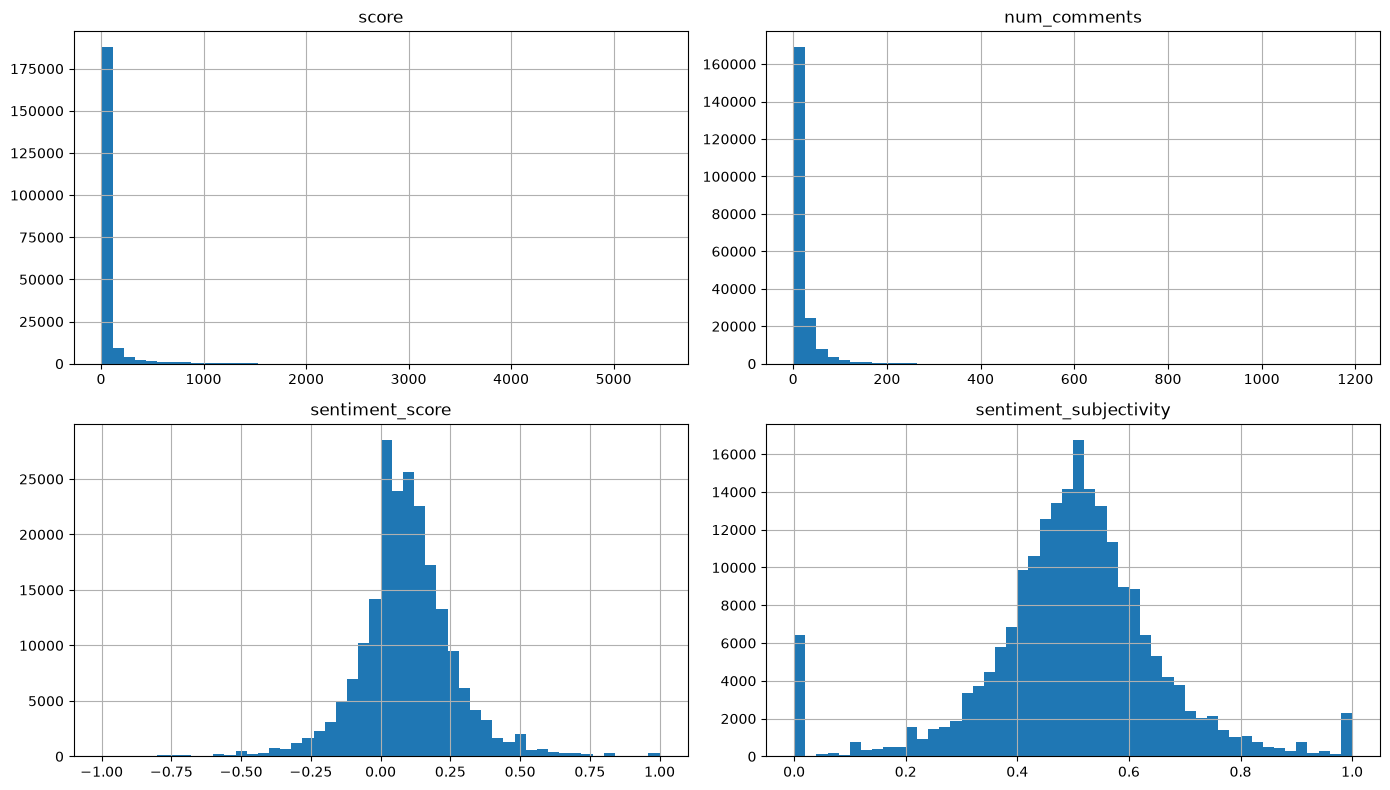

In [71]:
import matplotlib.pyplot as plt

cols = ['score', 'num_comments',
        'sentiment_score', 'sentiment_subjectivity']

filtered_df[cols].hist(bins=50, figsize=(14, 8))
plt.tight_layout(); plt.show()

sent_label
positive    127767
neutral      51542
negative     30950
Name: count, dtype: int64


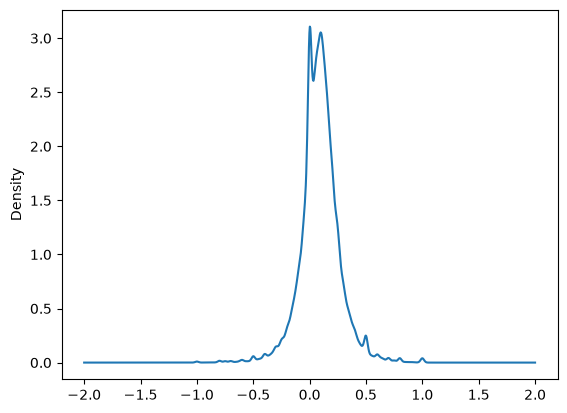

In [72]:
filtered_df['sentiment_score'].describe()
filtered_df['sentiment_score'].plot(kind='kde')

# Bucket it
filtered_df['sent_label'] = pd.cut(
    filtered_df['sentiment_score'],
    bins=[-1, -0.05, 0.05, 1],
    labels=['negative', 'neutral', 'positive']
)
print(filtered_df['sent_label'].value_counts())

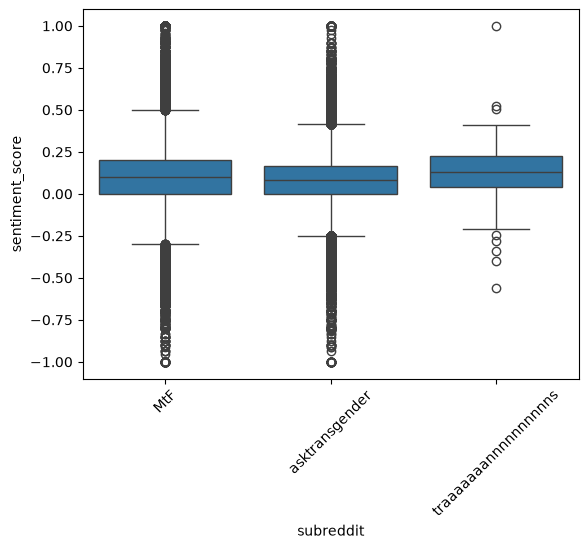

In [74]:
filtered_df.groupby('subreddit')['sentiment_score'].agg(['mean', 'median', 'count']) \
           .sort_values('mean')

import seaborn as sns
sns.boxplot(data=filtered_df, x='subreddit', y='sentiment_score')
plt.xticks(rotation=45); plt.show()

<Axes: >

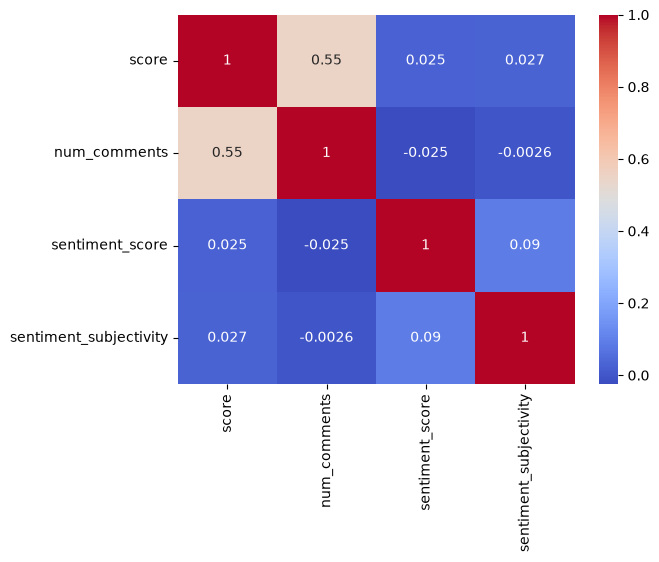

In [75]:
filtered_df[cols].corr()
sns.heatmap(filtered_df[cols].corr(), annot=True, cmap='coolwarm')

<Axes: xlabel='created_utc'>

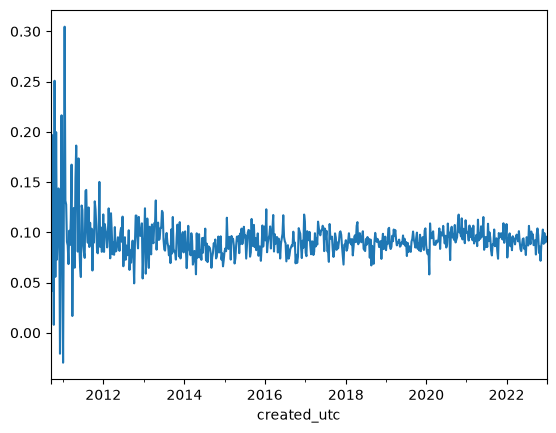

In [76]:
filtered_df['created_utc'] = pd.to_datetime(filtered_df['created_utc'], unit='s')
filtered_df.set_index('created_utc')['sentiment_score'].resample('W').mean().plot()

<Axes: >

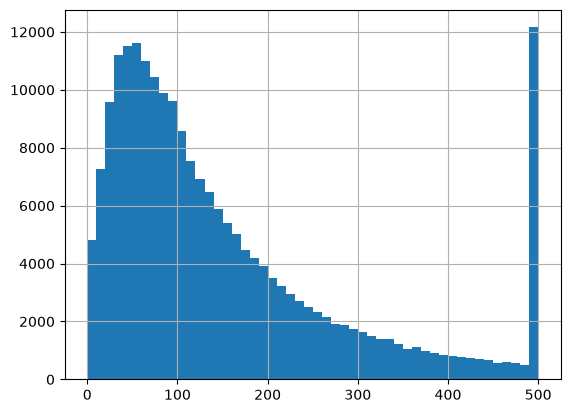

In [77]:
filtered_df['char_len'] = filtered_df['text'].str.len()
filtered_df['word_len'] = filtered_df['text'].str.split().str.len()

filtered_df[['char_len', 'word_len']].describe()
filtered_df['word_len'].clip(upper=500).hist(bins=50)

<Axes: >

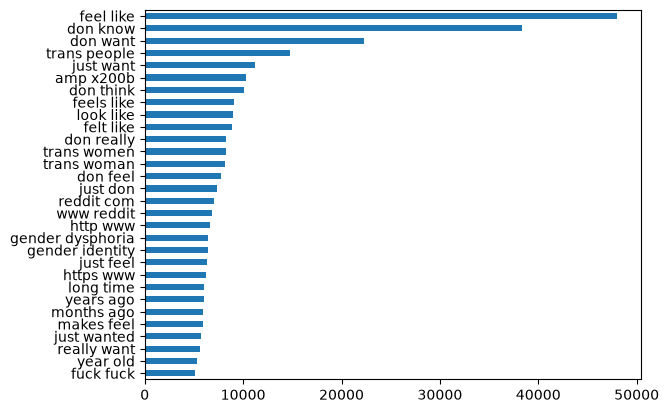

In [78]:
from sklearn.feature_extraction.text import CountVectorizer

vec = CountVectorizer(ngram_range=(2, 2), stop_words='english', min_df=5, max_features=30)
X = vec.fit_transform(filtered_df['text'].fillna(''))
pd.Series(X.sum(axis=0).A1, index=vec.get_feature_names_out()).sort_values().plot(kind='barh')

In [79]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


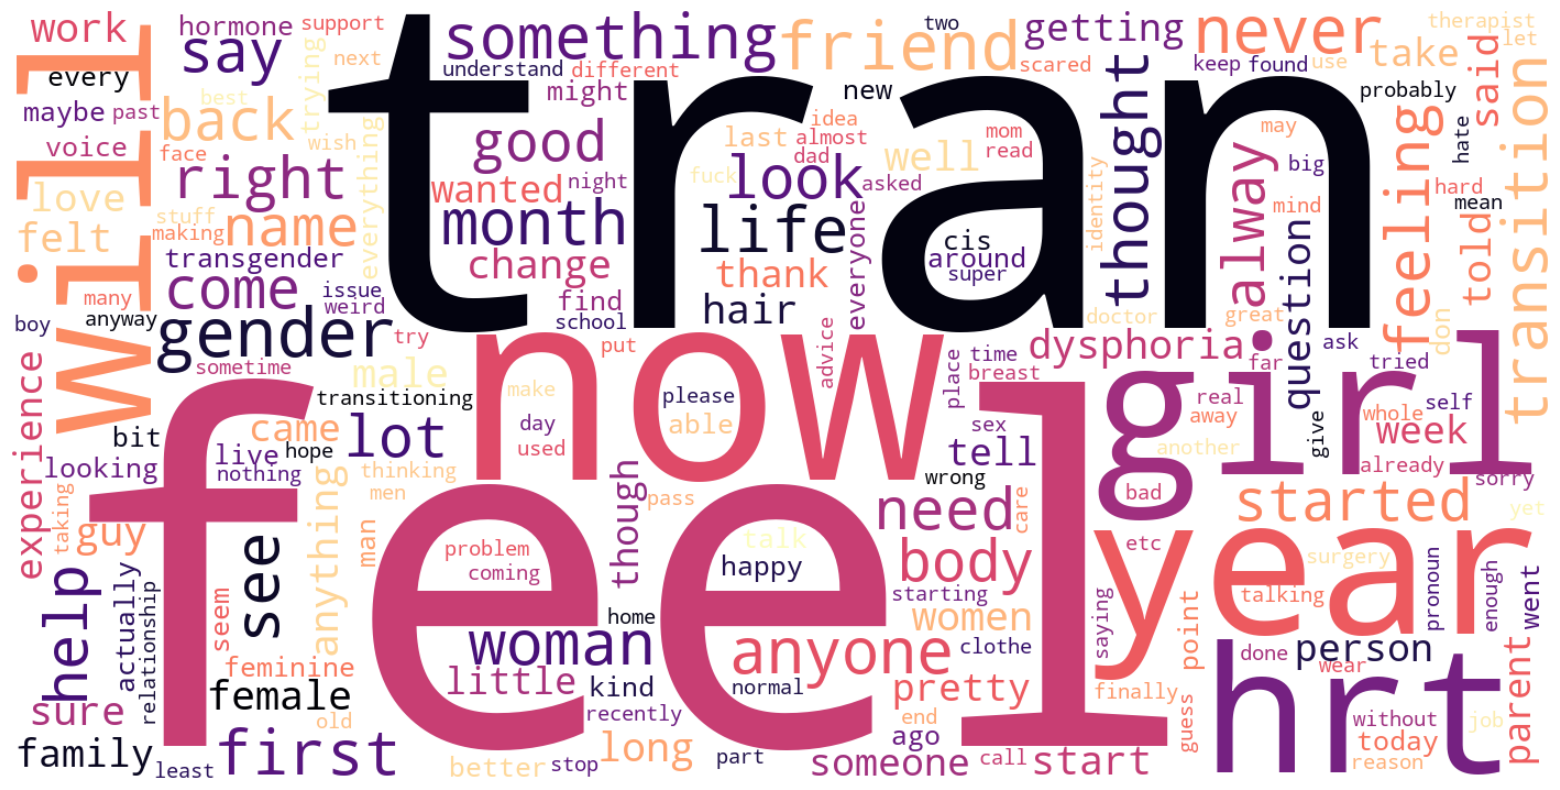

In [80]:
import re
from wordcloud import WordCloud, STOPWORDS

extra_stop = {
    'https', 'http', 'www', 'com', 'reddit', 'amp', 'gt', 'lt',
    'one', 'would', 'like', 'really', 'think', 'know', 'get', 'got',
    'also', 'even', 'much', 'still', 'want', 'make', 'made', 'go',
    'going', 'thing', 'things', 'people', 'time', 'way', 'day',
    'mtf', 'asktransgender', 'traaaaaaannnnnnnnnns', 'edit', 'post',
}
stop = STOPWORDS | extra_stop

def clean(t):
    t = str(t).lower()
    t = re.sub(r'http\S+|www\.\S+', ' ', t)      # URLs
    t = re.sub(r'\[.*?\]\(.*?\)', ' ', t)         # markdown links
    t = re.sub(r'[\[\]\(\)\{\}]', ' ', t)         # brackets
    t = re.sub(r'[^a-z\s\']', ' ', t)             # non-letters
    t = re.sub(r'\s+', ' ', t).strip()
    return t

tokens = []
for title, text in zip(filtered_df['title'].fillna(''), filtered_df['text'].fillna('')):
    tokens.extend(w for w in clean(title + ' ' + text).split()
                  if w not in stop and len(w) > 2)

text_blob = ' '.join(tokens)

wc = WordCloud(
    width=1400, height=700,
    background_color='white',
    max_words=200,
    colormap='magma',
    collocations=False,       # don't join bigrams
    random_state=42,
).generate(text_blob)

plt.figure(figsize=(16, 8))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.tight_layout()
plt.show()

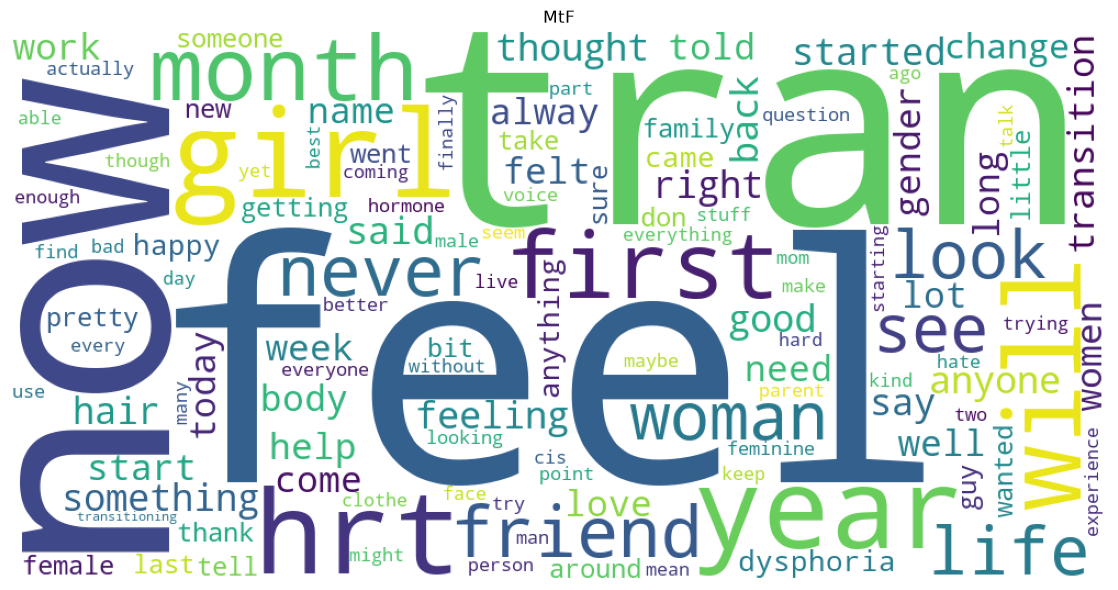

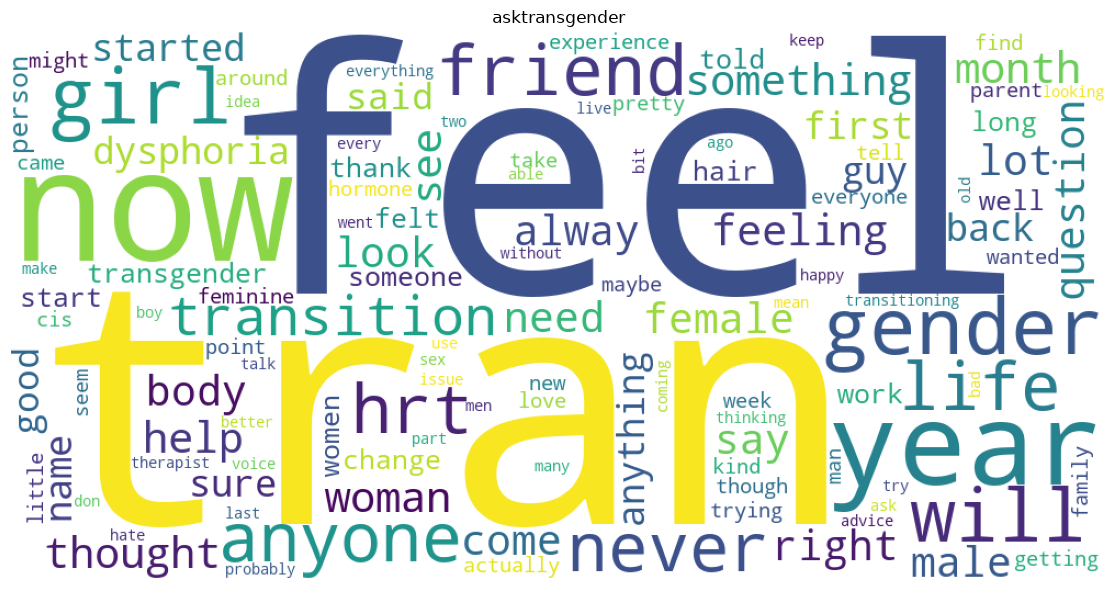

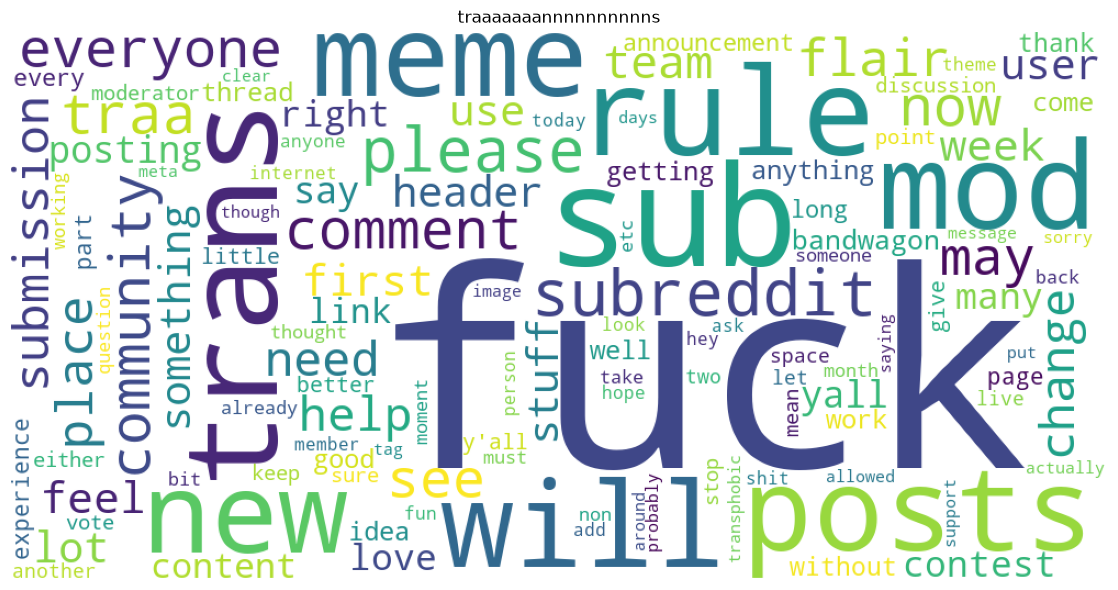

In [81]:
for sub, grp in filtered_df.groupby('subreddit'):
    blob = ' '.join(
        w for t in (grp['title'].fillna('') + ' ' + grp['text'].fillna(''))
        for w in clean(t).split() if w not in stop and len(w) > 2
    )
    if not blob.strip():
        continue
    wc = WordCloud(width=1000, height=500, background_color='white',
                   max_words=120, colormap='viridis',
                   collocations=False).generate(blob)
    plt.figure(figsize=(12, 6))
    plt.imshow(wc); plt.axis('off')
    plt.title(sub); plt.tight_layout()
    plt.savefig(f'wc_{sub}.png', dpi=150)
    plt.show()

Al ver las graficas de analisis, creo que no es tan bueno el analisis que se hizo. no es el mejor. por lo que utilizar un modelo basado en transformers nos dara un resultado bastante mejor. Pero eso será para la siguiente práctica :D